<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_083_neural_networks_forward_propagation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 83/365 — Neural Networks, Perceptrons & Forward Propagation

## Interview question
**How does a neural network actually produce a prediction?**

Today we build the intuition from the smallest unit:

**one neuron (perceptron)**

and then connect several neurons into a tiny neural network.

The core forward-pass equation is:

`z = w₁x₁ + w₂x₂ + ... + b`

Then we pass `z` through an activation function:

`a = f(z)`


In [1]:
import numpy as np
import matplotlib.pyplot as plt


## 1. One neuron by hand

Suppose:

- `x1 = 2`
- `x2 = 1`
- `w1 = 0.5`
- `w2 = -1`
- `bias = 0.5`

First compute the weighted sum.


In [2]:
x1 = 2
x2 = 1

w1 = 0.5
w2 = -1.0
bias = 0.5

z = w1*x1 + w2*x2 + bias

print("Weighted sum z =", z)


Weighted sum z = 0.5


Calculation:

`z = (0.5 × 2) + (-1 × 1) + 0.5`

`z = 1 - 1 + 0.5`

`z = 0.5`


## 2. Apply an activation function

For a binary-output example, we can use sigmoid:

`sigmoid(z) = 1 / (1 + e^-z)`

It converts any real number into a value between 0 and 1.


In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

output = sigmoid(z)

print("Neuron output =", output)


Neuron output = 0.6224593312018546


For `z = 0.5`:

`sigmoid(0.5) ≈ 0.622`

So this neuron outputs approximately:

`0.622`


## 3. Visualize sigmoid


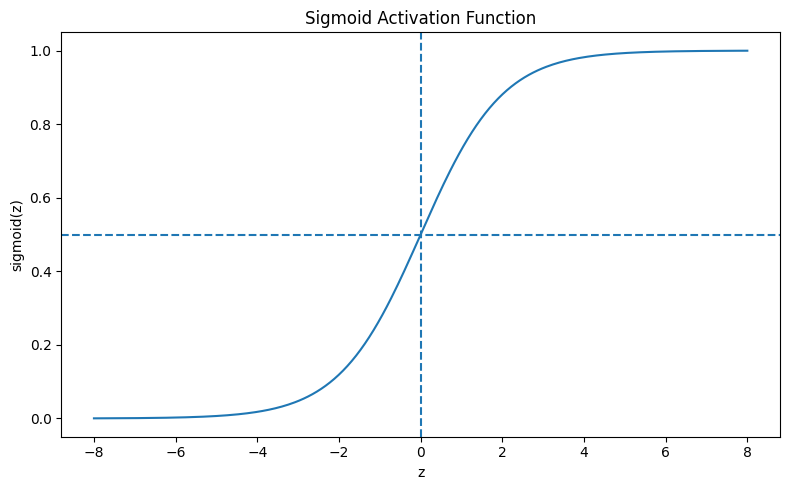

In [4]:
z_values = np.linspace(-8, 8, 300)
sigmoid_values = sigmoid(z_values)

plt.figure(figsize=(8,5))
plt.plot(z_values, sigmoid_values)
plt.axhline(0.5, linestyle="--")
plt.axvline(0, linestyle="--")
plt.xlabel("z")
plt.ylabel("sigmoid(z)")
plt.title("Sigmoid Activation Function")
plt.tight_layout()
plt.show()


## 4. From one neuron to a hidden layer

A neural network simply performs many weighted-sum + activation operations.

For a hidden layer:

`z¹ = W¹x + b¹`

`a¹ = f(z¹)`

Then the next layer receives `a¹` as its input.


In [5]:
# Two input features
x = np.array([2.0, 1.0])

# 3 neurons in the hidden layer
W1 = np.array([
    [0.5, -1.0],
    [1.0,  0.5],
    [-0.5, 1.0]
])

b1 = np.array([0.5, -0.5, 0.2])

z1 = W1 @ x + b1
a1 = sigmoid(z1)

print("Hidden weighted sums:", z1)
print("Hidden activations:", a1)


Hidden weighted sums: [0.5 2.  0.2]
Hidden activations: [0.62245933 0.88079708 0.549834  ]


## 5. Output layer

Now the hidden activations become the input to the output neuron.


In [6]:
W2 = np.array([0.7, -0.4, 0.9])
b2 = -0.2

z2 = W2 @ a1 + b2
prediction = sigmoid(z2)

print("Output weighted sum:", z2)
print("Final prediction:", prediction)


Output weighted sum: 0.3782532982313755
Final prediction: 0.5934517507252071


## 6. Forward propagation

The complete flow is:

`Input x`

↓

`z¹ = W¹x + b¹`

↓

`a¹ = activation(z¹)`

↓

`z² = W²a¹ + b²`

↓

`prediction = activation(z²)`

This movement from input to prediction is called:

**Forward Propagation**


## 7. Why do we need activation functions?

Without nonlinear activation functions, stacking many neural-network layers would still behave like one large linear transformation.

Activation functions let neural networks learn nonlinear relationships.

Popular activations include:

- ReLU
- Sigmoid
- Tanh
- Softmax

We will cover these next.


## 8. What is actually learned?

During training, the network changes:

- weights `W`
- biases `b`

The goal is to make predictions closer to the correct answers.

Forward propagation produces the prediction.

Then:

`Prediction → Loss Function → Backpropagation → Update Weights`

We will build those pieces progressively.


## Interview-ready answer

**What is forward propagation?**

Forward propagation is the process of passing input data through each neural-network layer to compute a prediction.

At each neuron:

1. multiply inputs by weights
2. add the bias
3. apply an activation function
4. pass the result to the next layer

Mathematically:

`z = Wx + b`

`a = f(z)`


## Enterprise intuition

A neural network could receive features such as:

`transaction amount, device risk, account age, velocity`

Each neuron learns different weighted combinations of these features.

Deeper layers combine simpler patterns into more complex representations.

The final layer converts those learned representations into a prediction.


## What does this teach?

- A perceptron is the basic computational unit of a neural network.
- Inputs are multiplied by weights.
- A bias is added.
- An activation function transforms the result.
- Layers pass activations forward.
- Forward propagation produces the model prediction.
- Training later adjusts the weights and biases to reduce error.

> **A neural network is not magic: at its core, it repeatedly performs weighted sums followed by nonlinear transformations.**


## References

- Deep Learning — Goodfellow, Bengio & Courville:
  https://www.deeplearningbook.org/

- Stanford CS231n — Neural Networks:
  https://cs231n.github.io/neural-networks-1/

- TensorFlow — Neural network classification:
  https://www.tensorflow.org/tutorials/keras/classification
